# 第18步：共同病例临床、MRI及融合Logistic模型

182次扫描/135名患者，肿瘤141次、治疗改变41次。固定4个主模型、同一套患者分组5折，唯一主要比较为Fusion−M1的AUC差。无调参、特征筛选或阈值优化。源标注盲法未确认，8位强度、未知空间单位及公开标签来源限制延续。

In [1]:
from pathlib import Path
import sys,json
import pandas as pd,numpy as np
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from rn_public.ucsd_fusion import freeze_plan,run,FEATURES
d,eroded,folds,lock=freeze_plan(ROOT)
print(folds.groupby('validation_fold').agg(scans=('ID','size'),patients=('patient_id','nunique'),tumor=('tumor_label','sum')))
print('Fixed model inputs:',json.dumps(FEATURES,ensure_ascii=False))
print('Input and protocol lock:',json.dumps(lock,indent=2))

                 scans  patients  tumor
validation_fold                        
1                   38        28     29
2                   36        26     28
3                   36        27     28
4                   36        27     28
5                   36        27     28
Fixed model inputs: {"M0": ["age_years", "sex_male"], "M1": ["age_years", "log_initial_event_days", "sex_male", "other_treatment_prior", "initial_event_missing"], "MRI": ["FLAIR_mean", "FLAIR_std", "FLAIR_entropy", "FLAIR_glcm_contrast", "T1post_mean", "T1post_std", "T1post_entropy", "T1post_glcm_contrast"], "Fusion": ["age_years", "log_initial_event_days", "sex_male", "other_treatment_prior", "initial_event_missing", "FLAIR_mean", "FLAIR_std", "FLAIR_entropy", "FLAIR_glcm_contrast", "T1post_mean", "T1post_std", "T1post_entropy", "T1post_glcm_contrast"]}
Input and protocol lock: {
  "seed": 20261029,
  "n_splits": 5,
  "protocol_sha256": "83c590fbff2abf2dbaf657d2e61995c7f15a573876bfb3f99108b0693a8dc3eb",
  "ana

只在训练折拟合填补及标准化。MRI敏感性整体替换为一次腐蚀特征，同病例同折。2,000次患者聚类配对bootstrap固定已有OOF概率，不重拟合训练过程。区间不覆盖全部训练/分折变异。

In [2]:
summary=run(ROOT)
print('Bootstrap valid / attempted:',summary['bootstrap_valid'],summary['bootstrap_attempts'])
print('Patient / BraTS-patient overlap:',summary['patient_overlap'],summary['brats_patient_overlap'])
print('No tuning:',not summary['hyperparameter_search'])

Paired patient bootstrap 250/2000
Paired patient bootstrap 500/2000
Paired patient bootstrap 750/2000
Paired patient bootstrap 1000/2000
Paired patient bootstrap 1250/2000
Paired patient bootstrap 1500/2000
Paired patient bootstrap 1750/2000
Paired patient bootstrap 2000/2000
Bootstrap valid / attempted: 2000 2000
Patient / BraTS-patient overlap: 0 0
No tuning: True


In [3]:
out=ROOT/'reports/ucsd_fusion'
metrics=pd.read_csv(out/'model_metrics.csv');comparisons=pd.read_csv(out/'paired_comparisons.csv')
print(metrics[['model','roc_auc','roc_auc_ci_lower','roc_auc_ci_upper','brier','ap_treatment_change','tn','fp','fn','tp']].to_string(index=False))
print(comparisons.to_string(index=False))
print('Calibration:',json.dumps(summary['calibration'],indent=2))

        model  roc_auc  roc_auc_ci_lower  roc_auc_ci_upper    brier  ap_treatment_change  tn  fp  fn  tp
           M0 0.525515          0.403964          0.644101 0.176697             0.261331   0  41   1 140
           M1 0.672116          0.553287          0.778100 0.163381             0.353557   2  39   7 134
          MRI 0.762498          0.682773          0.838467 0.151392             0.444433  12  29  13 128
       Fusion 0.781872          0.697690          0.859487 0.144234             0.505288  12  29  11 130
   MRI_eroded 0.765439          0.683564          0.843985 0.149488             0.458058  11  30   9 132
Fusion_eroded 0.788099          0.705915          0.867033 0.141007             0.529245  14  27   7 134
        prior 0.493081               NaN               NaN 0.174547             0.222892   0  41   0 141
                comparison              metric  difference     lower     upper  primary_comparison
           Fusion_minus_M1             roc_auc    0.109756  0

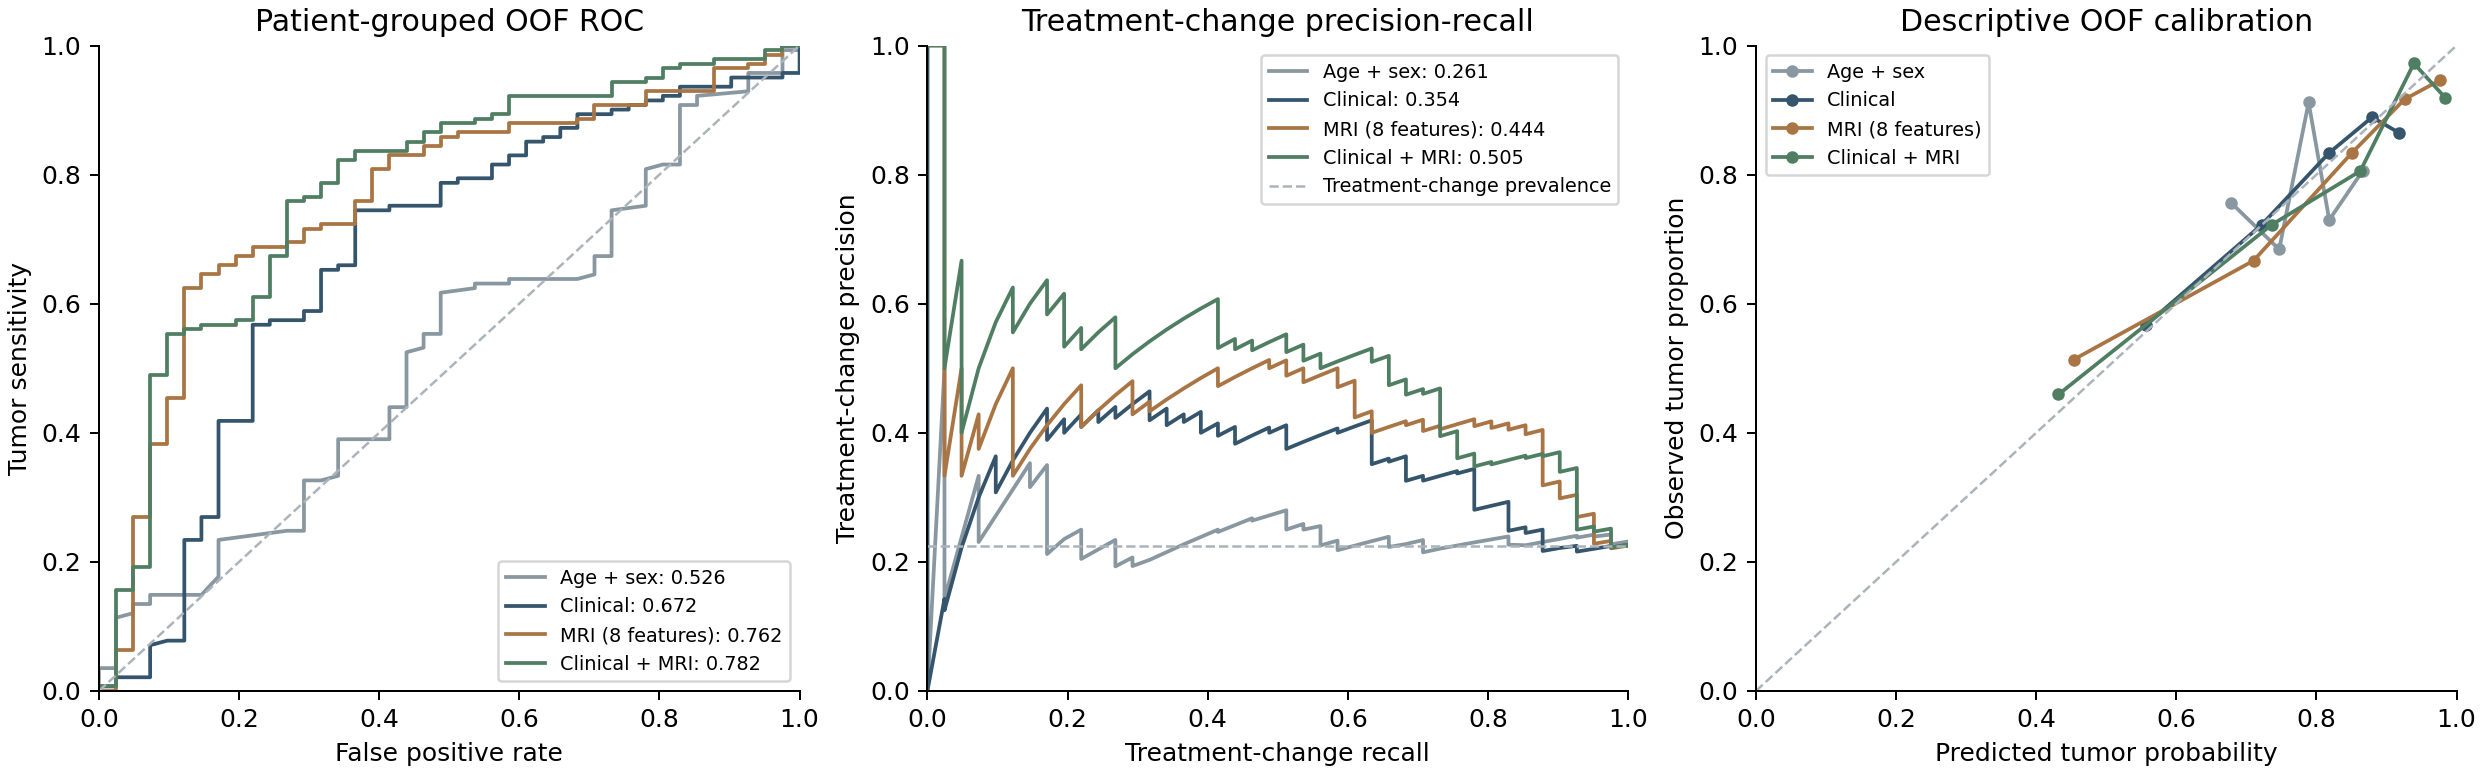

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('fusion_deliverables',ROOT/'scripts/make_ucsd_fusion_deliverables.py')
module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
module.generate(ROOT)
from IPython.display import display,Image
display(Image(filename=str(ROOT/'figures/ucsd_fusion/model_comparison.png')))
display(Image(filename=str(ROOT/'figures/ucsd_fusion/paired_and_boundary_comparison.png')))

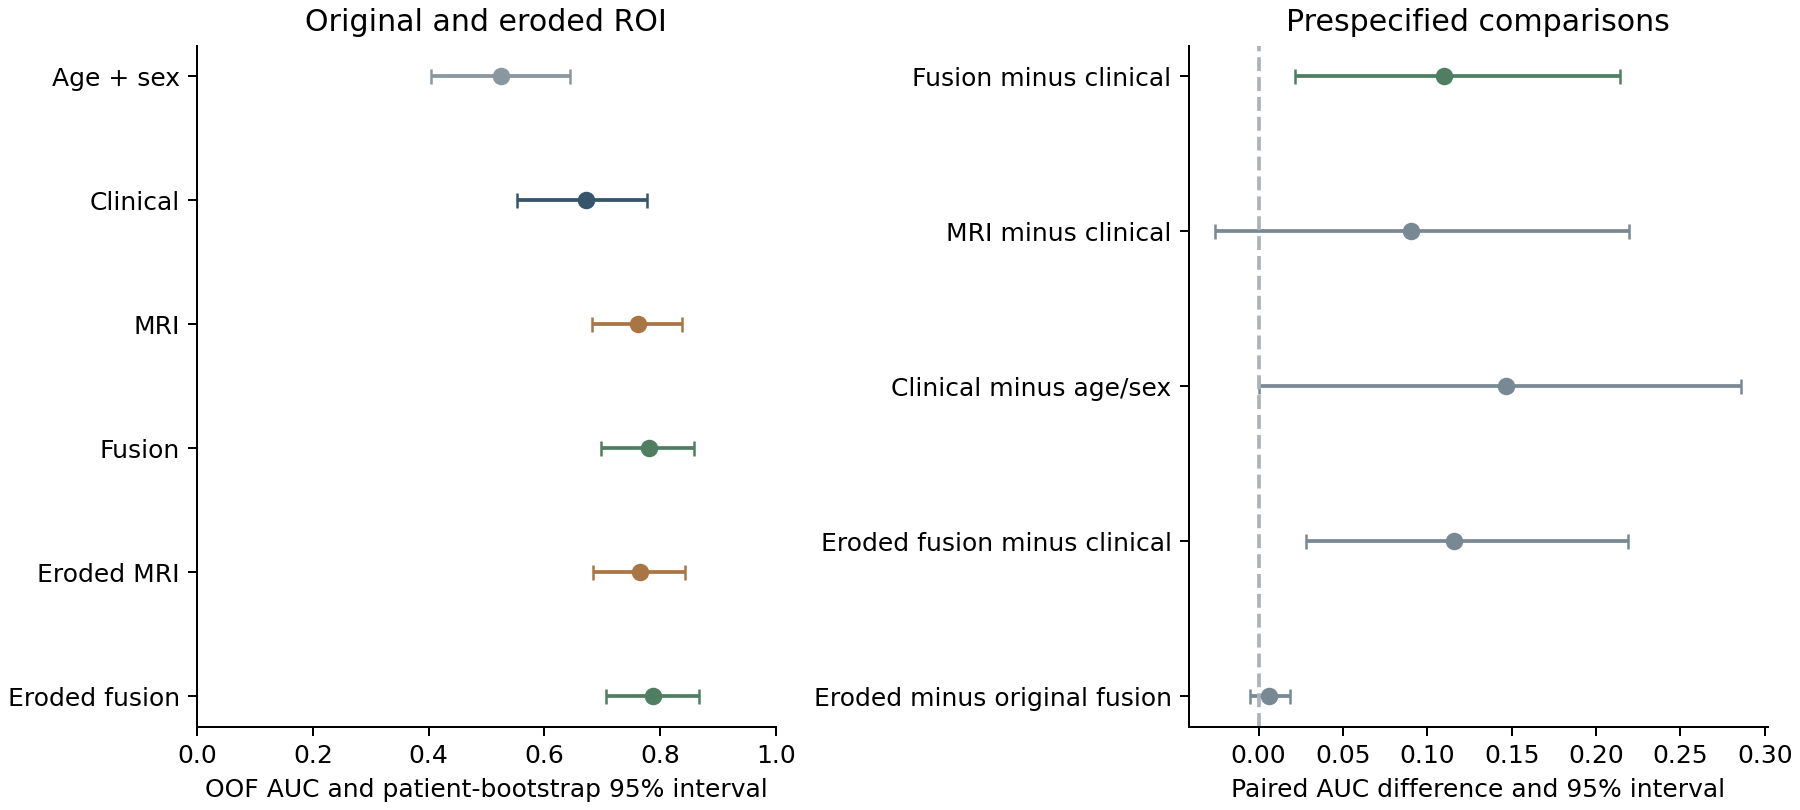

Input bytes, fixed folds and model code verified. Prior-stage results preserved.
Full-cohort coefficients describe fitted models; all displayed performance uses OOF predictions.


In [5]:
import hashlib
pred=pd.read_csv(ROOT/'data/processed/ucsd_fusion_oof.csv')
assert len(pred)==182 and pred.ID.is_unique
for key in ['patient_id','brats_patient_id','validation_group']:
    assert pred.groupby(key).validation_fold.nunique().eq(1).all()
for p,h in lock['input_sha256'].items():
    assert hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==h
assert hashlib.sha256((ROOT/'reports/ucsd_fusion_protocol.md').read_bytes()).hexdigest()==lock['protocol_sha256']
assert hashlib.sha256((ROOT/'src/rn_public/ucsd_fusion.py').read_bytes()).hexdigest()==lock['analysis_code_sha256']
print('Input bytes, fixed folds and model code verified. Prior-stage results preserved.')
print('Full-cohort coefficients describe fitted models; all displayed performance uses OOF predictions.')

本阶段到此结束。报告全部固定模型及腐蚀敏感性，不根据较高AUC改写主分析。内部验证、有限病例与分割来源限制使结果不能直接解释为临床可用；后续工作等待用户批准。